# PI5

# 🧠 Sistema de Recomendação por Afinidade — v3.0

**Pipeline:** Extração → Saneamento → EDA → Produto Mestre (Regex + Fuzzy) → FP-Growth → API FastAPI

### Melhorias aplicadas nesta versão (v3 sobre v2):
- ✅ **Fuzzy match** (RapidFuzz) integrado após o regex para fundir variações tipográficas
- ✅ `token_sort_ratio` como scorer — ignora ordem das palavras na comparação
- ✅ Canônico escolhido por frequência no catálogo (mais representativo)
- ✅ Célula de diagnóstico para calibrar o threshold antes de rodar
- ✅ Busca da API também usa fuzzy (não exige digitação exata)

### Todas as correções da v2 mantidas:
- ✅ FP-Growth no lugar do Apriori
- ✅ `map()` no lugar do depreciado `applymap()`
- ✅ Regras multi-item preservadas (antecedents/consequents completos)
- ✅ `mapear_nome` via dicionário O(1)
- ✅ Conexão com banco via `try/finally`

# CÉLULA 1 — INSTALAÇÃO DE DEPENDÊNCIAS

In [3]:
# ============================================================
# CÉLULA 1 — INSTALAÇÃO DE DEPENDÊNCIAS
# ============================================================
# Execute esta célula apenas uma vez no ambiente.
# RapidFuzz é muito mais rápido que fuzzywuzzy e não exige
# python-Levenshtein como dependência separada.
# ============================================================

import subprocess, sys

pkgs = [
    'rapidfuzz',
    'mlxtend',
    'fastapi',
    'uvicorn',
    'nest_asyncio',
]
for pkg in pkgs:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'], check=False)

print('✅ Dependências verificadas.')

✅ Dependências verificadas.


# CÉLULA 2 — IMPORTS E CONFIGURAÇÕES GLOBAIS

In [4]:
# ============================================================
# CÉLULA 2 — IMPORTS E CONFIGURAÇÕES GLOBAIS
# ============================================================

import re
import warnings
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import pypyodbc
import matplotlib.pyplot as plt
import seaborn as sns
from rapidfuzz import fuzz, process

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('future.no_silent_downcasting', True)

plt.style.use('seaborn-v0_8-muted')
sns.set_theme(style='whitegrid')


def conectar():
    """Retorna uma conexão ao banco HFSQL."""
    return pypyodbc.connect(
        'Driver={HFSQL};Server Name=localhost;Server Port=4900;'
        'Database=A37278473;UID=admin;PWD=;'
    )


print('✅ Imports e configurações carregados.')

✅ Imports e configurações carregados.


# CÉLULA 3 — EXTRAÇÃO E AUDITORIA DOS DATASETS

In [5]:
# ============================================================
# CÉLULA 3 — EXTRAÇÃO E AUDITORIA DOS DATASETS
# ============================================================
# Conexão usa try/finally para garantir que conn.close()
# é sempre chamado, mesmo em caso de exceção.
# ============================================================

def auditoria_e_exibicao_datasets():
    tabelas_alvo = ['TAB_VENDA_ITEM', 'TAB_VENDA', 'TAB_PRODUTO']
    datasets_finais = {}

    print('=' * 80)
    print(f"📋 ESCOPO DA ANÁLISE: {', '.join(tabelas_alvo)}")
    print('=' * 80)

    for tabela in tabelas_alvo:
        print(f'\n▶️  PROCESSANDO: {tabela}')
        conn = conectar()
        try:
            cursor = conn.cursor()

            cursor.execute(f'SELECT TOP 1 * FROM {tabela}')
            colunas_originais = [col[0] for col in cursor.description]
            print(f'   📊 Campos identificados: {len(colunas_originais)}')

            colunas_sql = ', '.join(
                [f'CAST({c} AS VARCHAR(255)) AS {c}' for c in colunas_originais]
            )
            cursor.execute(f'SELECT {colunas_sql} FROM {tabela}')
            df = pd.DataFrame(
                [list(r) for r in cursor.fetchall()], columns=colunas_originais
            )

            df = df.replace(r'^\s*$', np.nan, regex=True).replace('None', np.nan)
            total_rows = len(df)

            campos_integros = []
            campos_para_remover = []

            for col in colunas_originais:
                nulos    = df[col].isnull().sum()
                distintos = df[col].nunique()

                if nulos == 0:
                    campos_integros.append(col)

                if nulos == total_rows:
                    campos_para_remover.append((col, '100% Nulo'))
                elif distintos <= 1:
                    val = df[col].dropna().unique()[0] if distintos == 1 else 'Vazio'
                    campos_para_remover.append((col, f"Constante ('{val}') — sem variância"))

            print(f'   ✅ Campos 100% preenchidos: {len(campos_integros)}')

            if campos_para_remover:
                print('   ❌ Campos removidos:')
                for col_rem, motivo in campos_para_remover:
                    print(f'      - {col_rem}: {motivo}')
            else:
                print('   ✨ Nenhum campo removido.')

            cols_remover = [c[0] for c in campos_para_remover]
            df_final = df.drop(columns=cols_remover)
            datasets_finais[tabela] = df_final

            print(f'   📄 Resultado: {len(df_final.columns)} colunas × {total_rows} linhas.')

        except Exception as e:
            print(f'   💥 Erro ao processar {tabela}: {e}')
        finally:
            conn.close()

    return datasets_finais


datasets = auditoria_e_exibicao_datasets()

📋 ESCOPO DA ANÁLISE: TAB_VENDA_ITEM, TAB_VENDA, TAB_PRODUTO

▶️  PROCESSANDO: TAB_VENDA_ITEM
   📊 Campos identificados: 45
   ✅ Campos 100% preenchidos: 38
   ❌ Campos removidos:
      - obs: 100% Nulo
      - grade_id: Constante ('0') — sem variância
      - cor_id: Constante ('0') — sem variância
      - tabela: Constante ('1') — sem variância
      - altura: Constante ('0') — sem variância
      - largura: Constante ('0') — sem variância
      - altlar: Constante ('0') — sem variância
      - locacao_dt_ini: 100% Nulo
      - locacao_dt_fin: 100% Nulo
      - locacao_status: Constante ('0') — sem variância
      - sinal: Constante ('0') — sem variância
      - locacao_dt_prova: 100% Nulo
      - vendedor_id: Constante ('0') — sem variância
      - entrega_id: Constante ('0') — sem variância
      - tx_comissao: Constante ('0') — sem variância
      - endereco_ordem: Constante ('0') — sem variância
      - romaneio: Constante ('0') — sem variância
      - impresso: Constante ('0') — 

# CÉLULA 4 — EDA GERAL (FATURAMENTO, PRODUTOS, CESTAS)

📊 EDA — ANÁLISE EXPLORATÓRIA DE DADOS

📈 FATURAMENTO:
   Ticket Médio : R$ 46.50
   Valor Máximo : R$ 2257.70


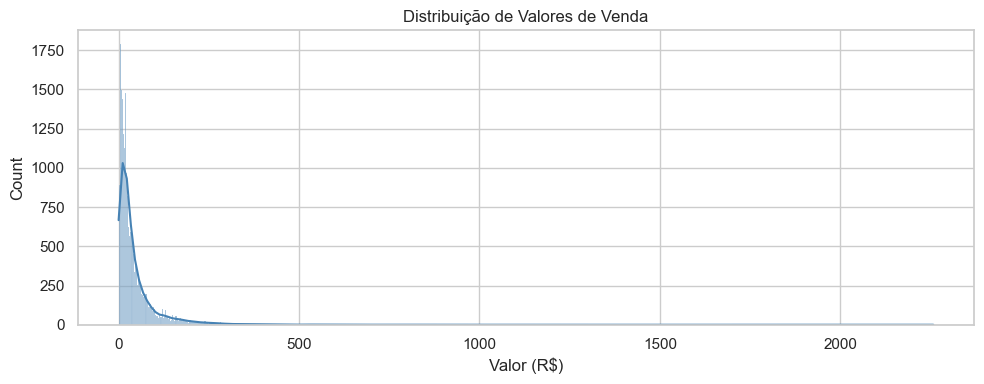

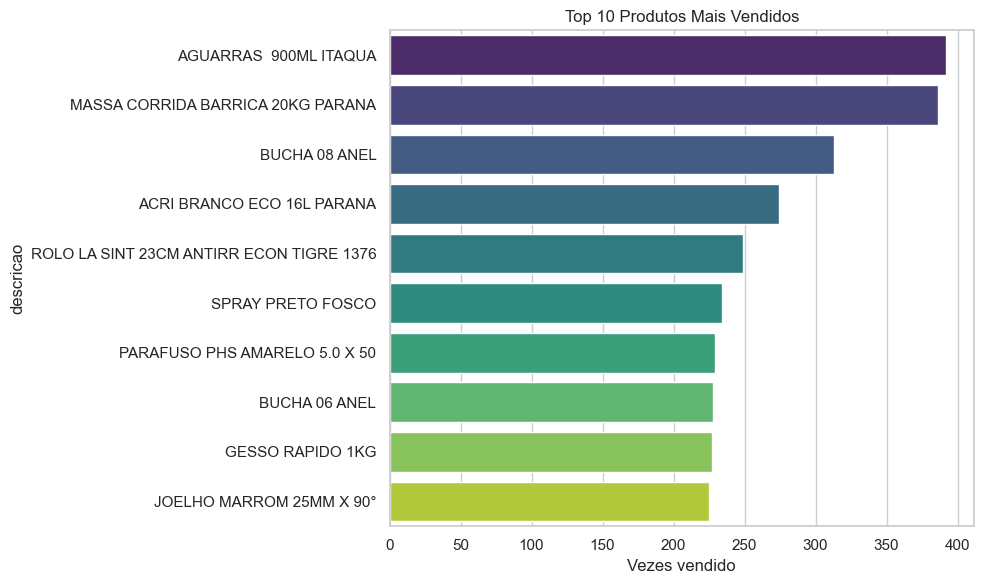


🛒 Média de itens por cupom: 2.06


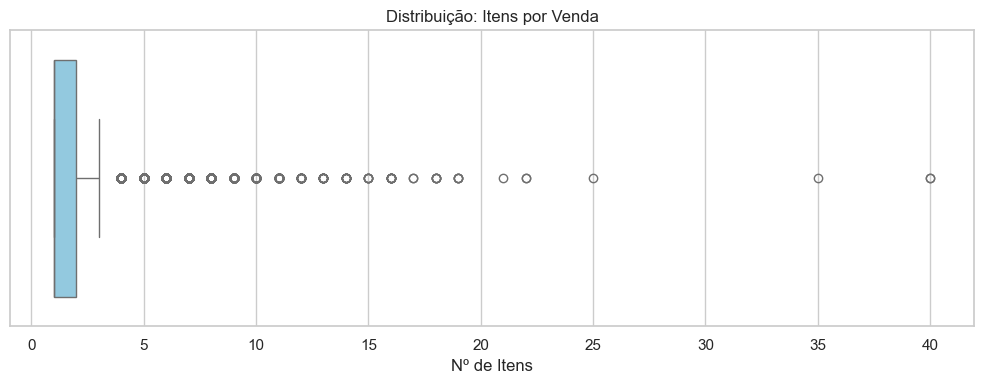

In [6]:
# ============================================================
# CÉLULA 4 — EDA GERAL (FATURAMENTO, PRODUTOS, CESTAS)
# ============================================================

def executar_eda_completa(datasets):
    print('=' * 80)
    print('📊 EDA — ANÁLISE EXPLORATÓRIA DE DADOS')
    print('=' * 80)

    # 1. Faturamento
    if 'TAB_VENDA' in datasets:
        df_v = datasets['TAB_VENDA'].copy()
        col_valor = 'ven_cur_subtotal'
        df_v[col_valor] = pd.to_numeric(df_v[col_valor], errors='coerce')

        print(f'\n📈 FATURAMENTO:')
        print(f'   Ticket Médio : R$ {df_v[col_valor].mean():.2f}')
        print(f'   Valor Máximo : R$ {df_v[col_valor].max():.2f}')

        plt.figure(figsize=(10, 4))
        sns.histplot(df_v[col_valor].dropna(), kde=True, color='steelblue')
        plt.title('Distribuição de Valores de Venda')
        plt.xlabel('Valor (R$)')
        plt.tight_layout()
        plt.show()

    # 2. Top produtos
    if 'TAB_VENDA_ITEM' in datasets:
        df_i = datasets['TAB_VENDA_ITEM']
        top_produtos = df_i['descricao'].value_counts().head(10)

        plt.figure(figsize=(10, 6))
        sns.barplot(x=top_produtos.values, y=top_produtos.index, palette='viridis')
        plt.title('Top 10 Produtos Mais Vendidos')
        plt.xlabel('Vezes vendido')
        plt.tight_layout()
        plt.show()

    # 3. Densidade de cesta
    if 'TAB_VENDA_ITEM' in datasets:
        itens_venda = df_i.groupby('ven_id').size()
        print(f'\n🛒 Média de itens por cupom: {itens_venda.mean():.2f}')

        plt.figure(figsize=(10, 4))
        sns.boxplot(x=itens_venda, color='skyblue')
        plt.title('Distribuição: Itens por Venda')
        plt.xlabel('Nº de Itens')
        plt.tight_layout()
        plt.show()

    # 4. Correlação numérica
    if 'TAB_VENDA_ITEM' in datasets:
        df_num = df_i.select_dtypes(include=['float64', 'int64'])
        if not df_num.empty:
            plt.figure(figsize=(8, 6))
            sns.heatmap(df_num.corr(), annot=True, cmap='coolwarm', fmt='.2f')
            plt.title('Matriz de Correlação')
            plt.tight_layout()
            plt.show()


executar_eda_completa(datasets)

# CÉLULA 5 — EDA DETALHADO DE VENDAS

🔢 MÉTRICAS ESTATÍSTICAS — TAB_VENDA
   Contagem      : 20132
   Faturamento   : R$ 936107.60
   Ticket Médio  : R$ 46.50
   Mediana       : R$ 22.55
   Desvio Padrão : R$ 81.30
   Mínimo        : R$ 0.00
   Máximo        : R$ 2257.70


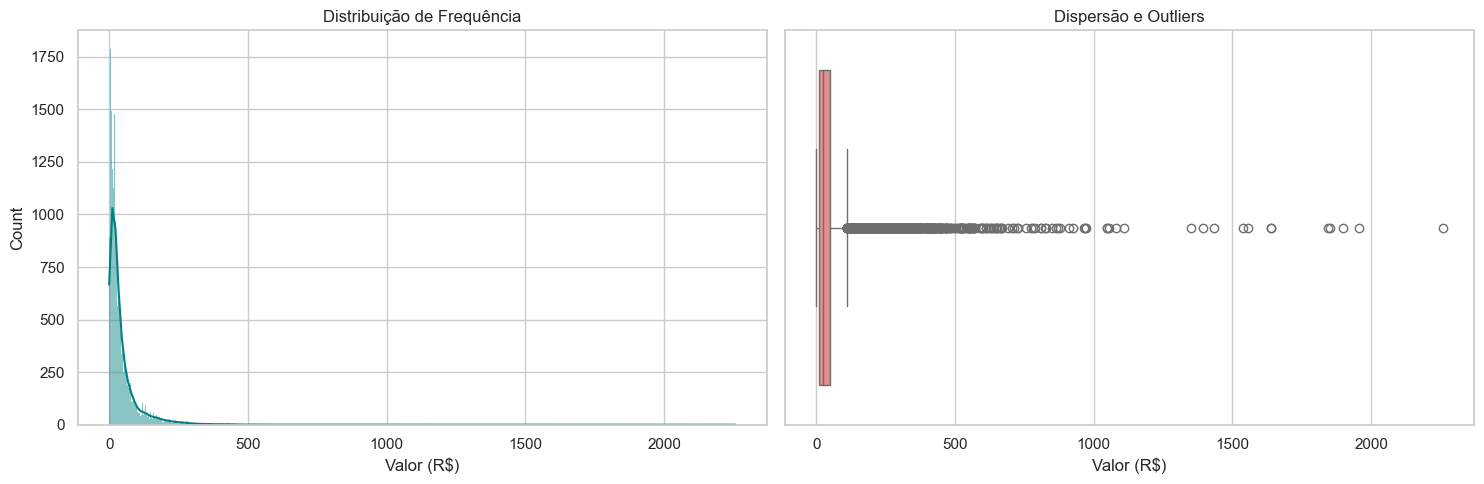

In [7]:
# ============================================================
# CÉLULA 5 — EDA DETALHADO DE VENDAS
# ============================================================

def eda_detalhado_vendas(datasets):
    if 'TAB_VENDA' not in datasets:
        print('❌ Dataset TAB_VENDA não encontrado.')
        return

    df = datasets['TAB_VENDA'].copy()
    col_valor = 'ven_cur_subtotal'
    df[col_valor] = pd.to_numeric(df[col_valor], errors='coerce')

    print('=' * 60)
    print('🔢 MÉTRICAS ESTATÍSTICAS — TAB_VENDA')
    print('=' * 60)
    s = df[col_valor].describe()
    print(f"   Contagem      : {int(s['count'])}")
    print(f"   Faturamento   : R$ {df[col_valor].sum():.2f}")
    print(f"   Ticket Médio  : R$ {s['mean']:.2f}")
    print(f"   Mediana       : R$ {df[col_valor].median():.2f}")
    print(f"   Desvio Padrão : R$ {s['std']:.2f}")
    print(f"   Mínimo        : R$ {s['min']:.2f}")
    print(f"   Máximo        : R$ {s['max']:.2f}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    sns.histplot(df[col_valor].dropna(), kde=True, color='teal', ax=ax1)
    ax1.set_title('Distribuição de Frequência')
    ax1.set_xlabel('Valor (R$)')

    sns.boxplot(x=df[col_valor].dropna(), color='lightcoral', ax=ax2)
    ax2.set_title('Dispersão e Outliers')
    ax2.set_xlabel('Valor (R$)')

    plt.tight_layout()
    plt.show()


eda_detalhado_vendas(datasets)

# CÉLULA 6 — SANEAMENTO: REMOÇÃO DE VENDAS ZERADAS

In [8]:
# ============================================================
# CÉLULA 6 — SANEAMENTO: REMOÇÃO DE VENDAS ZERADAS
# ============================================================

def filtrar_vendas_invalidas(datasets):
    if 'TAB_VENDA' not in datasets:
        print('❌ TAB_VENDA não encontrada.')
        return datasets

    df_vendas = datasets['TAB_VENDA'].copy()
    col_valor  = 'ven_cur_subtotal'
    df_vendas[col_valor] = pd.to_numeric(df_vendas[col_valor], errors='coerce')

    total_original = len(df_vendas)
    df_limpo = df_vendas[
        (df_vendas[col_valor] > 0) & df_vendas[col_valor].notna()
    ]
    total_atual  = len(df_limpo)
    qtd_excluida = total_original - total_atual
    pct          = (qtd_excluida / total_original) * 100

    datasets['TAB_VENDA'] = df_limpo

    print('=' * 60)
    print('🛡️  SANEAMENTO: VENDAS ZERADAS')
    print('=' * 60)
    print(f'   Registros originais  : {total_original}')
    print(f'   Excluídos (valor≤0)  : {qtd_excluida} ({pct:.2f}%)')
    print(f'   Dataset válido       : {total_atual} registros')

    return datasets


datasets = filtrar_vendas_invalidas(datasets)

🛡️  SANEAMENTO: VENDAS ZERADAS
   Registros originais  : 20132
   Excluídos (valor≤0)  : 224 (1.11%)
   Dataset válido       : 19908 registros


# CÉLULA 7 — EDA PARA RECOMENDAÇÃO (AFINIDADE E CO-OCORRÊNCIA)

🧠 EDA: ANÁLISE DE AFINIDADE PARA RECOMENDAÇÃO
   Itens antes            : 41381
   Itens após saneamento  : 40887
   Excluídos              : 494 (1.19%)
--------------------------------------------------------------------------------
📊 Esparsidade da matriz : 99.9466%
🛒 Média de itens/venda  : 1.99


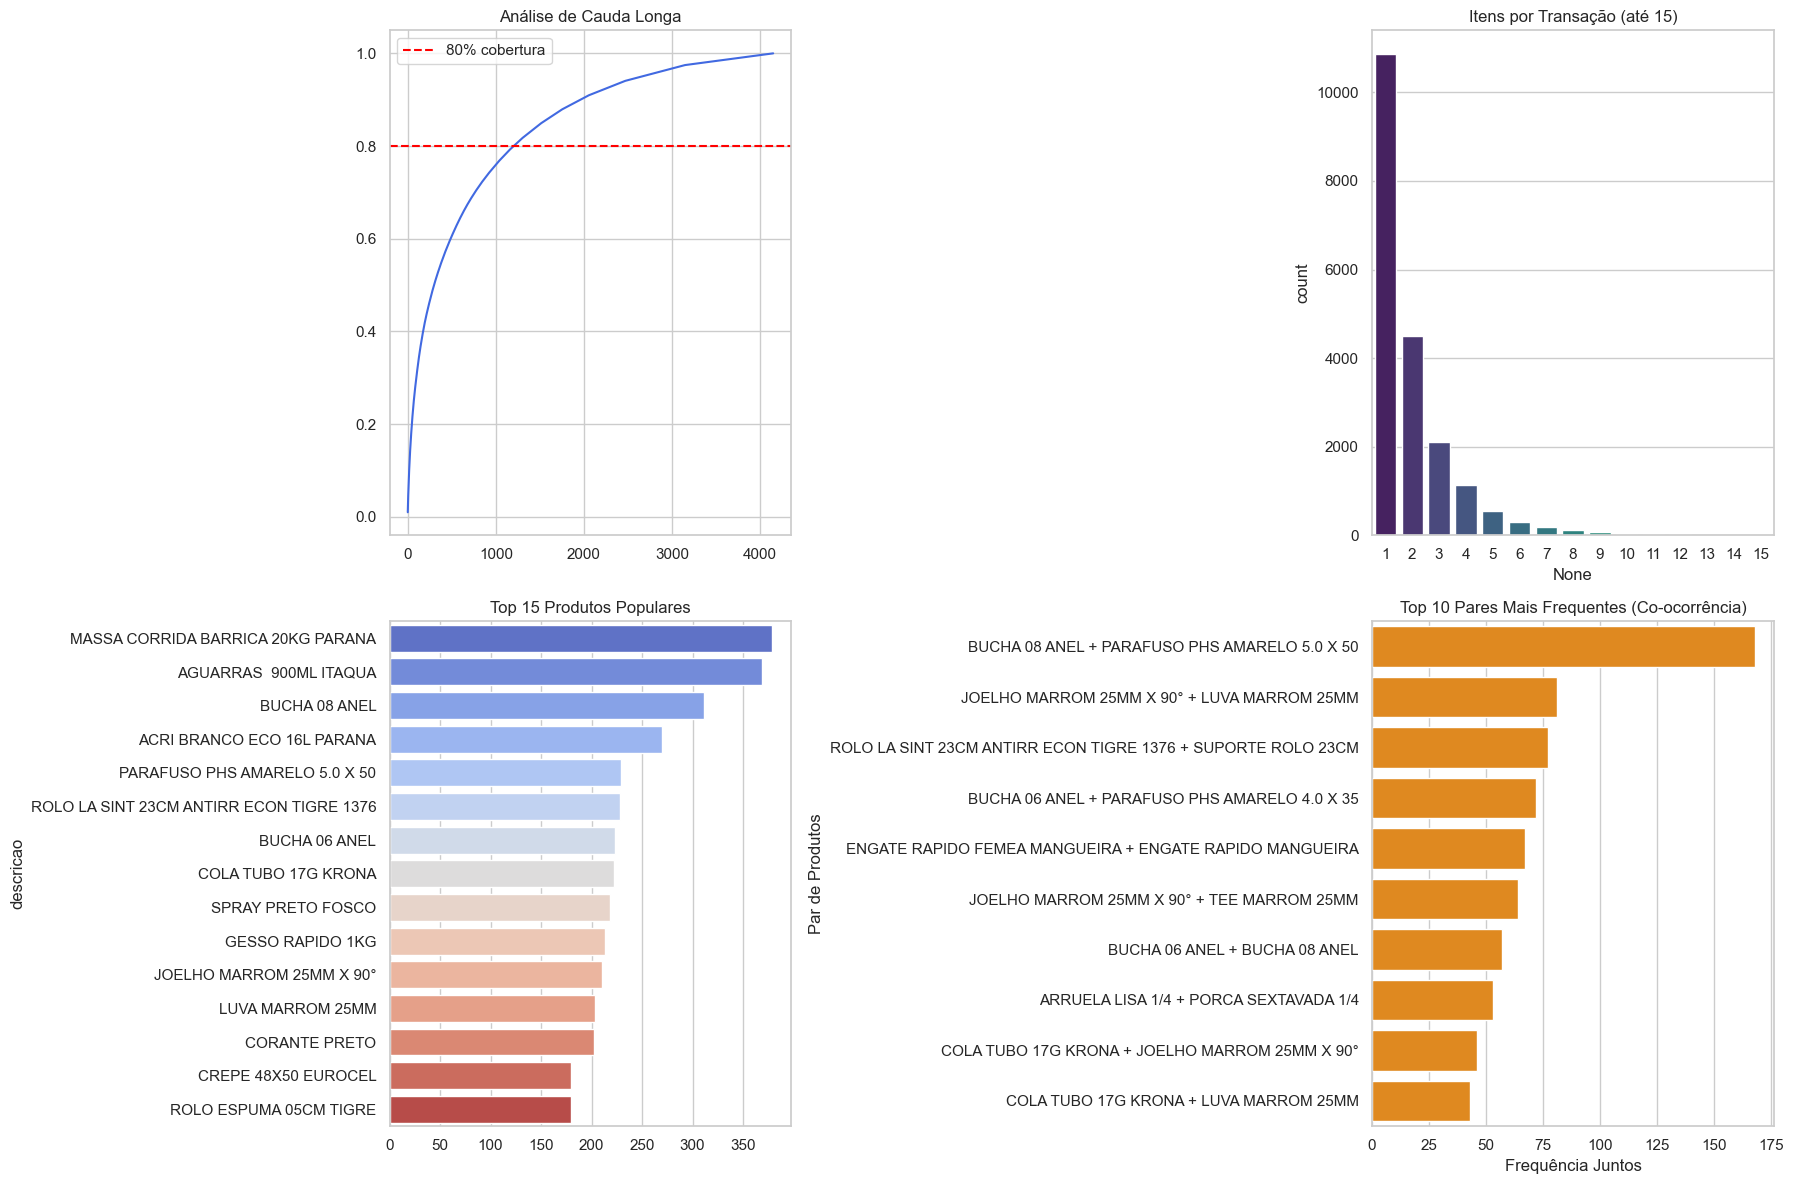

In [9]:
# ============================================================
# CÉLULA 7 — EDA PARA RECOMENDAÇÃO (AFINIDADE E CO-OCORRÊNCIA)
# ============================================================

def eda_recomendacao_venda_item(datasets):
    if 'TAB_VENDA_ITEM' not in datasets or 'TAB_VENDA' not in datasets:
        print('❌ Tabelas necessárias ausentes.')
        return datasets

    df_vendas   = datasets['TAB_VENDA']
    df_itens_raw = datasets['TAB_VENDA_ITEM']

    total_antes = len(df_itens_raw)
    df = df_itens_raw[df_itens_raw['ven_id'].isin(df_vendas['ven_id'])].copy()
    total_depois = len(df)
    qtd_excluida = total_antes - total_depois
    pct = (qtd_excluida / total_antes) * 100 if total_antes > 0 else 0

    df_presenca = df.drop_duplicates(subset=['ven_id', 'pro_id'])

    print('=' * 80)
    print('🧠 EDA: ANÁLISE DE AFINIDADE PARA RECOMENDAÇÃO')
    print('=' * 80)
    print(f'   Itens antes            : {total_antes}')
    print(f'   Itens após saneamento  : {total_depois}')
    print(f'   Excluídos              : {qtd_excluida} ({pct:.2f}%)')
    print('-' * 80)

    n_vendas = df['ven_id'].nunique()
    n_itens  = df['pro_id'].nunique()
    esparsidade = 0
    if n_vendas > 0 and n_itens > 0:
        esparsidade = (1 - len(df_presenca) / (n_vendas * n_itens)) * 100

    cesta_size = df_presenca.groupby('ven_id').size()

    print(f'📊 Esparsidade da matriz : {esparsidade:.4f}%')
    print(f'🛒 Média de itens/venda  : {cesta_size.mean():.2f}')

    # Top pares de co-ocorrência
    vendas_agrupadas = df_presenca.groupby('ven_id')['descricao'].apply(list)
    pares = Counter()
    for itens in vendas_agrupadas:
        if len(itens) > 1:
            pares.update(combinations(sorted(itens), 2))

    top_pares_data = [
        {'Par de Produtos': f'{p1} + {p2}', 'Frequência Juntos': freq}
        for (p1, p2), freq in pares.most_common(10)
    ]
    top_pares = pd.DataFrame(top_pares_data)

    fig, ax = plt.subplots(2, 2, figsize=(18, 12))

    item_counts = df_presenca['descricao'].value_counts(normalize=True).cumsum()
    ax[0, 0].plot(range(len(item_counts)), item_counts.values, color='royalblue')
    ax[0, 0].axhline(y=0.8, color='red', linestyle='--', label='80% cobertura')
    ax[0, 0].set_title('Análise de Cauda Longa')
    ax[0, 0].legend()

    sns.countplot(x=cesta_size.clip(upper=15), ax=ax[0, 1], palette='viridis')
    ax[0, 1].set_title('Itens por Transação (até 15)')

    top_15 = df_presenca['descricao'].value_counts().head(15)
    sns.barplot(x=top_15.values, y=top_15.index, ax=ax[1, 0], palette='coolwarm')
    ax[1, 0].set_title('Top 15 Produtos Populares')

    if not top_pares.empty:
        sns.barplot(
            data=top_pares, x='Frequência Juntos', y='Par de Produtos',
            ax=ax[1, 1], color='darkorange'
        )
        ax[1, 1].set_title('Top 10 Pares Mais Frequentes (Co-ocorrência)')

    plt.tight_layout()
    plt.show()

    datasets['TAB_VENDA_ITEM'] = df
    return datasets


datasets = eda_recomendacao_venda_item(datasets)

# CÉLULA 8 — ANÁLISE SEMÂNTICA / NLP DE DESCRIÇÕES

📝 ANÁLISE SEMÂNTICA — pro_txt_descricao
   Produtos únicos        : 5051
   Padrões 3-gram repetidos: 1665


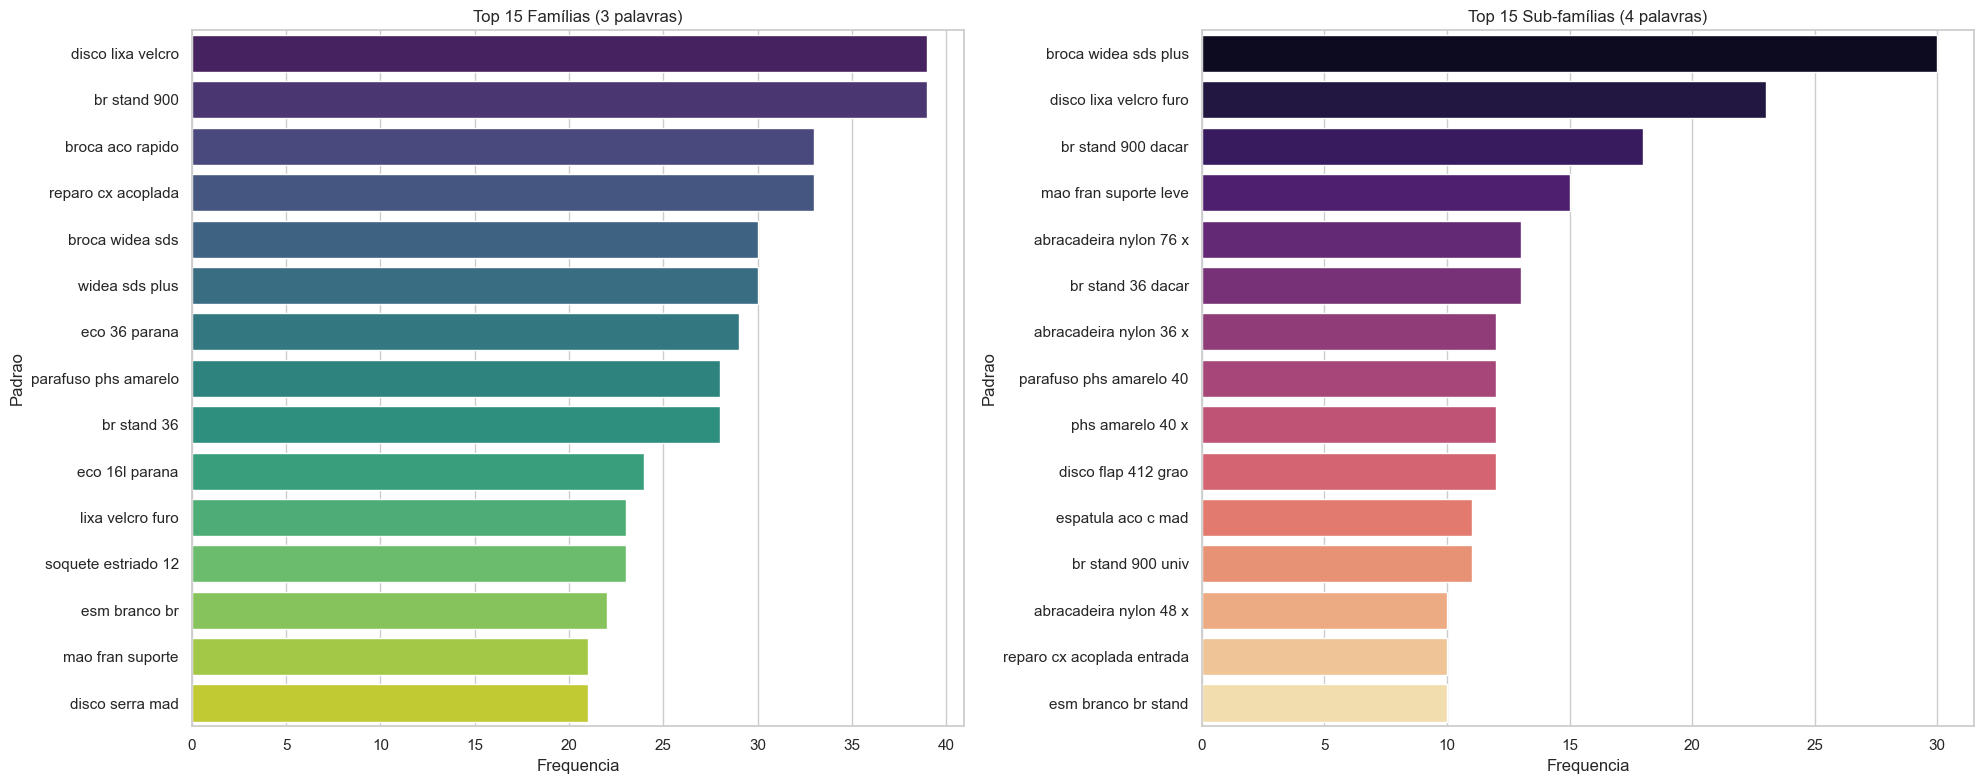


🔍 CLUSTERS POR PREFIXO (>= 3 variações):
   📦 [ABRACADEIRA NYLON 25]: 4 variações
      Exemplos: ['ABRACADEIRA NYLON 2,5 X 200 PT UN', 'ABRACADEIRA NYLON 2,5 X 150 BR UN', 'ABRACADEIRA NYLON 2,5 X 150 PT UN']
   📦 [ABRACADEIRA NYLON 36]: 13 variações
      Exemplos: ['ABRACADEIRA NYLON 3,6 X 150 BR UN', 'ABRACADEIRA NYLON 3,6 X 300 UN', 'ABRACADEIRA NYLON 3,6 X 200 BR UN']
   📦 [ABRACADEIRA NYLON 48]: 10 variações
      Exemplos: ['ABRACADEIRA NYLON 4,8 X 200 UN PT', 'ABRACADEIRA NYLON 4,8 X 400 UN', 'ABRACADEIRA NYLON 4,8 X 300 BR']
   📦 [ABRACADEIRA NYLON 76]: 13 variações
      Exemplos: ['ABRACADEIRA NYLON 7,6 X 400 PT', 'ABRACADEIRA NYLON 7,6 X 400 BR', 'ABRACADEIRA NYLON 7,6 X 500 PT UN']
   📦 [ACABAMENTO VOLANTE METAL]: 5 variações
      Exemplos: ['ACABAMENTO VOLANTE METAL C23', 'ACABAMENTO VOLANTE METAL C64', 'ACABAMENTO VOLANTE METAL C33']
   📦 [ACRI ALGODAO EGIP]: 7 variações
      Exemplos: ['ACRI ALGODAO EGIP 18L PARANA', 'ACRI ALGODAO EGIP TRADICAO 18L', 'ACRI ALGODAO E

In [10]:
# ============================================================
# CÉLULA 8 — ANÁLISE SEMÂNTICA / NLP DE DESCRIÇÕES
# ============================================================

def eda_robustez_textual(datasets):
    if 'TAB_PRODUTO' not in datasets:
        print('❌ TAB_PRODUTO não encontrada.')
        return datasets

    df_p     = datasets['TAB_PRODUTO'].copy()
    col_desc = 'pro_txt_descricao'

    def limpar_texto(txt):
        txt = str(txt).lower()
        txt = re.sub(r'[^\w\s]', '', txt)
        return txt.strip()

    def extrair_ngramas(txt, n):
        palavras = txt.split()
        if len(palavras) < n:
            return []
        return [' '.join(palavras[i:i+n]) for i in range(len(palavras) - n + 1)]

    df_p['desc_clean'] = df_p[col_desc].apply(limpar_texto)

    ngrams_3, ngrams_4 = [], []
    for d in df_p['desc_clean']:
        ngrams_3.extend(extrair_ngramas(d, 3))
        ngrams_4.extend(extrair_ngramas(d, 4))

    df_ng3 = pd.DataFrame(Counter(ngrams_3).most_common(15), columns=['Padrao', 'Frequencia'])
    df_ng4 = pd.DataFrame(Counter(ngrams_4).most_common(15), columns=['Padrao', 'Frequencia'])

    print('=' * 80)
    print(f'📝 ANÁLISE SEMÂNTICA — {col_desc}')
    print('=' * 80)
    print(f'   Produtos únicos        : {len(df_p)}')
    print(f'   Padrões 3-gram repetidos: {len([k for k, v in Counter(ngrams_3).items() if v > 1])}')

    fig, ax = plt.subplots(1, 2, figsize=(20, 8))
    sns.barplot(data=df_ng3, x='Frequencia', y='Padrao', palette='viridis', ax=ax[0])
    ax[0].set_title('Top 15 Famílias (3 palavras)')
    sns.barplot(data=df_ng4, x='Frequencia', y='Padrao', palette='magma', ax=ax[1])
    ax[1].set_title('Top 15 Sub-famílias (4 palavras)')
    plt.tight_layout()
    plt.show()

    print('\n🔍 CLUSTERS POR PREFIXO (>= 3 variações):')
    df_p['prefixo_3'] = df_p['desc_clean'].apply(lambda x: ' '.join(x.split()[:3]))
    grupos = df_p.groupby('prefixo_3')[col_desc].apply(list)
    for prefixo, lista in grupos.items():
        if len(lista) >= 3:
            print(f'   📦 [{prefixo.upper()}]: {len(lista)} variações')
            print(f'      Exemplos: {lista[:3]}')

    return datasets


datasets = eda_robustez_textual(datasets)

# CÉLULA 9 — DIAGNÓSTICO DE THRESHOLD (CALIBRAÇÃO)

In [11]:
# ============================================================
# CÉLULA 9 — DIAGNÓSTICO DE THRESHOLD (CALIBRAÇÃO)
# ============================================================
# Execute esta célula ANTES de criar o produto mestre.
# Ela mostra os pares na zona cinzenta para você decidir
# se o threshold está correto para seus dados.
#
# Leitura dos resultados:
#   Score > 90  → quase certamente o mesmo produto
#   Score 75-90 → avaliar manualmente (zona cinzenta)
#   Score < 75  → provavelmente produtos diferentes
# ============================================================

def diagnosticar_threshold(datasets, amostra=300, score_min=75, score_max=92):
    if 'TAB_PRODUTO' not in datasets:
        print('❌ TAB_PRODUTO não encontrada.')
        return

    df_p = datasets['TAB_PRODUTO'].copy()

    # Aplica o mesmo regex da etapa seguinte para comparar
    def extrair_mestre_bruto(txt):
        txt = str(txt).upper()
        txt = re.sub(r'\d+\s*(ML|KG|G|GR|UN|LT|L|CX|PCT|UNIDADE)', '', txt)
        txt = re.sub(r'[^\w\s]', '', txt)
        palavras = txt.split()
        return ' '.join(palavras[:3]) if len(palavras) >= 3 else ' '.join(palavras)

    mestres = df_p['pro_txt_descricao'].apply(extrair_mestre_bruto).unique().tolist()
    amostra_mestres = mestres[:amostra]  # limita para não travar

    print('=' * 70)
    print(f'🔬 DIAGNÓSTICO DE THRESHOLD (scores entre {score_min} e {score_max})')
    print(f'   Analisando {len(amostra_mestres)} mestres (amostra de {len(mestres)} únicos)')
    print('=' * 70)

    pares_zona_cinzenta = []
    vistos = set()

    for mestre in amostra_mestres:
        hits = process.extract(
            mestre,
            amostra_mestres,
            scorer=fuzz.token_sort_ratio,
            score_cutoff=score_min,
            limit=10
        )
        for h_txt, h_score, _ in hits:
            if h_txt == mestre:
                continue
            chave = tuple(sorted([mestre, h_txt]))
            if chave in vistos:
                continue
            vistos.add(chave)
            if score_min <= h_score <= score_max:
                pares_zona_cinzenta.append((h_score, mestre, h_txt))

    pares_zona_cinzenta.sort(reverse=True)

    if not pares_zona_cinzenta:
        print('   ✅ Nenhum par ambíguo encontrado na faixa especificada.')
        print('   Sugestão: o threshold padrão de 82 parece seguro para esses dados.')
        return

    print(f'\n   {len(pares_zona_cinzenta)} pares na zona cinzenta — avalie manualmente:\n')
    print(f'   {"Score":>5}  {"Mestre A":<35}  {"Mestre B"}')
    print('   ' + '-' * 80)
    for score, a, b in pares_zona_cinzenta[:40]:  # mostra até 40 pares
        print(f'   {score:>5}  {a:<35}  {b}')

    print('\n💡 Se os pares acima SÃO o mesmo produto → aumente o threshold ou abaixe score_max')
    print('   Se os pares acima SÃO produtos diferentes → abaixe o threshold')


diagnosticar_threshold(datasets)

🔬 DIAGNÓSTICO DE THRESHOLD (scores entre 75 e 92)
   Analisando 300 mestres (amostra de 3123 únicos)

   209 pares na zona cinzenta — avalie manualmente:

   Score  Mestre A                             Mestre B
   --------------------------------------------------------------------------------
    92.0  TORNEIRA TANQUEMAQUINA C33           TORNEIRA TANQUEMAQUINA 2
   91.89189189189189  PORCA SEXTAVADA 516                  PORCA SEXTAVADA 14
   91.66666666666666  ABRACADEIRA MANGOTE 6775             ABRACADEIRA MANGOTE 7987
   91.42857142857143  CHURRAS INOX MEDIA                   CHURRAS INOX MESA
   90.9090909090909  TUBO ESGOTO 40MM                     TUBO ESGOTO 100MM
   90.9090909090909  TUBO ESGOTO 100MM                    TUBO ESGOTO 50MM
   90.32258064516128  ABRACADEIRA U 34                     ABRACADEIRA U 2
    90.0  REGISTRO PRESSAO C64                 REGISTRO PRESSAO C52
    90.0  REGISTRO PRESSAO C64                 REGISTRO PRESSAO C50
    90.0  REGISTRO PRESSAO C52  

# CÉLULA 10 — CRIAÇÃO DO PRODUTO MESTRE (REGEX + FUZZY)

In [12]:
# ============================================================
# CÉLULA 10 — CRIAÇÃO DO PRODUTO MESTRE (REGEX + FUZZY)
# ============================================================
#
# Fluxo de dois estágios:
#
# ETAPA 1 — Regex:
#   Remove unidades de medida (ML, KG, G...) e pontuação,
#   extrai as 3 primeiras palavras como chave canônica.
#   Resultado: reduz dimensão, mas ainda falha em abreviações
#   e variações tipográficas (INTEG vs INTEGRAL).
#
# ETAPA 2 — Fuzzy match (RapidFuzz / token_sort_ratio):
#   Agrupa mestres com similaridade >= threshold em uma única
#   entidade canônica. O canônico escolhido é o mais frequente
#   no catálogo (mais representativo dos dados reais).
#   token_sort_ratio ordena as palavras antes de comparar,
#   resolvendo casos como "PILAO CAFE TORRADO" vs "CAFE TORRADO PILAO".
#
# Ajuste o threshold com base na célula de diagnóstico acima.
# ============================================================

def criar_produto_mestre(datasets, threshold=82):
    """
    threshold : similaridade mínima (0-100) para dois mestres serem fundidos.
                82 é um bom ponto de partida para dados de varejo.
                Calibre usando a célula de diagnóstico acima.
    """
    if 'TAB_PRODUTO' not in datasets:
        print('❌ TAB_PRODUTO não encontrada.')
        return datasets

    df_prod = datasets['TAB_PRODUTO'].copy()

    # ── ETAPA 1: Regex ──────────────────────────────────────
    def extrair_mestre_regex(txt):
        txt = str(txt).upper()
        txt = re.sub(r'\d+\s*(ML|KG|G|GR|UN|LT|L|CX|PCT|UNIDADE)', '', txt)
        txt = re.sub(r'[^\w\s]', '', txt)
        palavras = txt.split()
        return ' '.join(palavras[:3]) if len(palavras) >= 3 else ' '.join(palavras)

    df_prod['pro_txt_mestre'] = df_prod['pro_txt_descricao'].apply(extrair_mestre_regex)
    mestres_pos_regex = df_prod['pro_txt_mestre'].unique().tolist()

    print('=' * 70)
    print(f'🏗️  PRODUTO MESTRE — REGEX + FUZZY (threshold={threshold})')
    print('=' * 70)
    print(f'   SKUs originais          : {len(df_prod)}')
    print(f'   Mestres após regex      : {len(mestres_pos_regex)}')
    print(f'   ⚙️  Executando fuzzy match...')

    # ── ETAPA 2: Fuzzy match ────────────────────────────────
    # Frequência de cada mestre no catálogo (para escolher o canônico)
    freq_mestre = df_prod['pro_txt_mestre'].value_counts().to_dict()

    mapa_fusao = {}   # { variante: canônico }

    for mestre in mestres_pos_regex:
        # Se já foi absorvido por outro canônico, pula
        if mestre in mapa_fusao:
            continue

        # Busca todos os mestres com similaridade >= threshold
        resultados = process.extract(
            mestre,
            mestres_pos_regex,
            scorer=fuzz.token_sort_ratio,   # ignora ordem das palavras
            score_cutoff=threshold,
            limit=30
        )

        candidatos = [r[0] for r in resultados]

        # Canônico = o mais frequente no catálogo (mais representativo)
        canonical = max(candidatos, key=lambda x: freq_mestre.get(x, 0))

        for c in candidatos:
            mapa_fusao[c] = canonical

    # Aplica o mapa de fusão
    df_prod['pro_txt_mestre'] = df_prod['pro_txt_mestre'].map(mapa_fusao)

    # Fallback: se algum mestre ficou sem mapeamento, usa ele mesmo
    df_prod['pro_txt_mestre'] = df_prod['pro_txt_mestre'].fillna(
        df_prod['pro_txt_descricao'].apply(extrair_mestre_regex)
    )

    mestres_pos_fuzzy = df_prod['pro_txt_mestre'].nunique()
    fusoes_realizadas = len(mestres_pos_regex) - mestres_pos_fuzzy
    reducao_total     = ((len(df_prod) - mestres_pos_fuzzy) / len(df_prod)) * 100

    print(f'   Mestres após fuzzy      : {mestres_pos_fuzzy}')
    print(f'   Fusões realizadas       : {fusoes_realizadas}')
    print(f'   Redução total de dimensão: {reducao_total:.2f}%')

    # ── ETAPA 3: Agrupamento final ───────────────────────────
    df_mestre = df_prod.groupby('pro_txt_mestre').agg(
        lista_ids_originais=('pro_id', list),
        exemplo_descricao=('pro_txt_descricao', 'first')
    ).reset_index()

    df_mestre['pro_id_mestre'] = range(5000, 5000 + len(df_mestre))

    print(f'   Entidades mestres geradas: {len(df_mestre)}')

    datasets['TAB_PRODUTO']          = df_prod
    datasets['DATASET_PRODUTO_MESTRE'] = df_mestre
    return datasets


# Ajuste o threshold com base no diagnóstico da célula anterior
datasets = criar_produto_mestre(datasets, threshold=82)

🏗️  PRODUTO MESTRE — REGEX + FUZZY (threshold=82)
   SKUs originais          : 5051
   Mestres após regex      : 3123
   ⚙️  Executando fuzzy match...
   Mestres após fuzzy      : 1938
   Fusões realizadas       : 1185
   Redução total de dimensão: 61.63%
   Entidades mestres geradas: 1938


# CÉLULA 11 — TABELA DE VÍNCULO (DE-PARA SKU → MESTRE)

In [13]:
# ============================================================
# CÉLULA 11 — TABELA DE VÍNCULO (DE-PARA SKU → MESTRE)
# ============================================================

def criar_tabela_vinculo(datasets):
    df_mestre = datasets['DATASET_PRODUTO_MESTRE'].copy()

    df_vinculo = df_mestre.explode('lista_ids_originais').rename(
        columns={'lista_ids_originais': 'pro_id'}
    )[['pro_id', 'pro_id_mestre', 'pro_txt_mestre']]

    print(f'🔗 Tabela de vínculo: {len(df_vinculo)} SKUs mapeados para {df_vinculo["pro_id_mestre"].nunique()} mestres.')
    datasets['TAB_VINCULO_MESTRE'] = df_vinculo
    return datasets


datasets = criar_tabela_vinculo(datasets)

🔗 Tabela de vínculo: 5051 SKUs mapeados para 1938 mestres.


# CÉLULA 12 — PREPARAÇÃO DO INPUT PARA O MODELO

In [14]:
# ============================================================
# CÉLULA 12 — PREPARAÇÃO DO INPUT PARA O MODELO
# ============================================================

def preparar_input_final_ia(datasets):
    df_itens   = datasets['TAB_VENDA_ITEM'].copy()
    df_vinculo = datasets['TAB_VINCULO_MESTRE']

    df_final = pd.merge(df_itens, df_vinculo, on='pro_id', how='inner')

    # Presença única: mesma venda + mesmo mestre → conta como 1
    df_input_ia = df_final[['ven_id', 'pro_id_mestre']].drop_duplicates()

    print('=' * 80)
    print('🚀 DATASET PRONTO PARA TREINAMENTO')
    print('=' * 80)
    print(f'   Transações processadas       : {len(df_final)}')
    print(f'   Registros de presença únicos : {len(df_input_ia)}')
    print(f'   Vendas distintas             : {df_input_ia["ven_id"].nunique()}')
    print(f'   Produtos mestres distintos   : {df_input_ia["pro_id_mestre"].nunique()}')

    datasets['TAB_VENDA_ITEM_MESTRE'] = df_final
    datasets['INPUT_IA_RECOMENDACAO'] = df_input_ia
    return datasets


datasets = preparar_input_final_ia(datasets)

🚀 DATASET PRONTO PARA TREINAMENTO
   Transações processadas       : 40887
   Registros de presença únicos : 37716
   Vendas distintas             : 19908
   Produtos mestres distintos   : 1587


# CÉLULA 13 — TREINAMENTO: FP-GROWTH + REGRAS DE ASSOCIAÇÃO

In [15]:
# ============================================================
# CÉLULA 13 — TREINAMENTO: FP-GROWTH + REGRAS DE ASSOCIAÇÃO
# ============================================================
#
# Por que FP-Growth e não Apriori?
#   O Apriori gera candidatos exaustivamente (O(2^n)).
#   O FP-Growth usa uma árvore compacta (FP-tree) para
#   encontrar os mesmos padrões em O(n), sem gerar candidatos.
#   Mesma interface do mlxtend — troca de uma linha.
#
# Correções sobre a v1 original:
#   1. map() no lugar do depreciado applymap()
#   2. antecedents/consequents preservados como conjuntos completos
#   3. mapear_nome via dicionário O(1) em vez de busca linear em loop
# ============================================================

import asyncio
import uvicorn
import nest_asyncio
from fastapi import FastAPI
from fastapi.responses import HTMLResponse
from mlxtend.frequent_patterns import fpgrowth, association_rules

nest_asyncio.apply()


def treinar_ia_mestre(datasets):
    print('=' * 80)
    print('🧠 TREINANDO IA COM FP-GROWTH')
    print('=' * 80)

    df_input  = datasets['INPUT_IA_RECOMENDACAO']
    df_mestre = datasets['DATASET_PRODUTO_MESTRE']

    # ── Filtrar vendas com ao menos 2 itens ──────────────────
    contagem_itens = df_input.groupby('ven_id').size()
    vendas_validas = contagem_itens[contagem_itens >= 2].index
    df_treino      = df_input[df_input['ven_id'].isin(vendas_validas)].copy()

    qtd_antes  = df_input['ven_id'].nunique()
    qtd_depois = len(vendas_validas)
    print(f'   Vendas de item único removidas : {qtd_antes - qtd_depois}')
    print(f'   Treinando com                  : {qtd_depois} vendas multi-item')

    if df_treino.empty:
        print('❌ Não restaram vendas com mais de um item.')
        return pd.DataFrame()

    # ── Matriz de presença (One-Hot booleana) ────────────────
    basket = (
        df_treino
        .groupby(['ven_id', 'pro_id_mestre'])
        .size()
        .unstack(fill_value=0)
    )

    # map() — substitui o depreciado applymap()
    basket_bool = basket.map(lambda x: True if x >= 1 else False)

    # ── FP-Growth ────────────────────────────────────────────
    print('\n   ⚙️  Executando FP-Growth...')
    frequent_itemsets = fpgrowth(
        basket_bool,
        min_support=0.001,
        use_colnames=True
    )

    if frequent_itemsets.empty:
        print('⚠️  Nenhum padrão encontrado. Tente reduzir min_support.')
        return pd.DataFrame()

    print(f'   Itemsets frequentes : {len(frequent_itemsets)}')

    # ── Geração das regras ───────────────────────────────────
    rules = association_rules(
        frequent_itemsets,
        metric='lift',
        min_threshold=1.0
    )

    # ── Dicionário O(1) para lookup de nomes ─────────────────
    mapa_nomes = df_mestre.set_index('pro_id_mestre')['pro_txt_mestre'].to_dict()

    def ids_para_nomes(itemset):
        """Converte frozenset de IDs em string legível."""
        return ' + '.join(mapa_nomes.get(i, str(i)) for i in itemset)

    # ── Monta DataFrame de regras ────────────────────────────
    # antecedents e consequents são preservados como conjuntos completos
    # (corrige o bug original que pegava apenas [0] e perdia {A,B}→{C})
    regras_finais = [
        {
            'busca':         ids_para_nomes(row['antecedents']),
            'recomendado':   ids_para_nomes(row['consequents']),
            'confianca_num': row['confidence'],
            'confianca_txt': f"{round(row['confidence'] * 100, 1)}%",
            'lift':          round(row['lift'], 2),
            'suporte':       round(row['support'], 4),
        }
        for _, row in rules.iterrows()
    ]

    df_recs = pd.DataFrame(regras_finais)
    print(f'   ✅ {len(df_recs)} regras de associação geradas.')
    return df_recs

# CÉLULA 14 — API FASTAPI

In [16]:
# ============================================================
# CÉLULA 14 — API FASTAPI
# ============================================================
# Melhoria v3: busca na API também usa fuzzy match.
# O endpoint /api/busca aceita digitação aproximada e
# retorna os produtos mais próximos mesmo com erros.
# ============================================================

app = FastAPI(title='IA de Venda Casada', version='3.0')
db_conhecimento   = pd.DataFrame()
catalogo_busca    = pd.DataFrame()
catalogo_detalhado = {}


@app.get('/', response_class=HTMLResponse)
async def interface_pdv():
    return '''
    <!DOCTYPE html>
    <html lang="pt-BR">
    <head>
        <meta charset="UTF-8">
        <title>IA Venda Casada v3</title>
        <style>
            *, *::before, *::after { box-sizing: border-box; margin: 0; padding: 0; }
            body {
                font-family: "Segoe UI", sans-serif;
                background: #f0f2f5;
                min-height: 100vh;
                padding: 32px;
            }
            header { text-align: center; margin-bottom: 28px; }
            header h1 { font-size: 1.6rem; color: #1a73e8; }
            header p  { color: #5f6368; font-size: 0.85rem; margin-top: 4px; }
            .container {
                max-width: 1020px; margin: auto;
                display: grid; grid-template-columns: 1fr 1fr; gap: 24px;
            }
            .panel {
                background: #fff; border-radius: 12px;
                padding: 24px; box-shadow: 0 2px 12px rgba(0,0,0,0.08);
            }
            h2 {
                font-size: 1rem; color: #1a73e8; margin-bottom: 14px;
                border-bottom: 2px solid #e8f0fe; padding-bottom: 8px;
            }
            .search-wrap { position: relative; }
            input[type=text] {
                width: 100%; padding: 11px 14px;
                border: 1px solid #ddd; border-radius: 8px;
                font-size: 15px; outline: none; transition: 0.2s;
            }
            input:focus { border-color: #1a73e8; box-shadow: 0 0 0 3px rgba(26,115,232,.15); }
            .badge-fuzzy {
                position: absolute; right: 10px; top: 50%;
                transform: translateY(-50%);
                font-size: 10px; color: #7f8c8d;
                background: #f1f3f4; padding: 2px 6px; border-radius: 4px;
            }
            #lista_resultados { margin-top: 12px; }
            .item-lista {
                padding: 10px 12px; border-bottom: 1px solid #f1f3f4;
                cursor: pointer; border-radius: 6px; transition: 0.15s;
            }
            .item-lista:hover { background: #e8f0fe; }
            .item-lista strong { display: block; font-size: 0.9rem; }
            .item-lista small  { color: #7f8c8d; font-size: 0.75rem; }
            .status-text { font-style: italic; color: #5f6368; margin-bottom: 12px; font-size: 0.88rem; }
            .card-rec {
                border: 1px solid #c3e6cb; border-radius: 10px;
                padding: 14px; margin-bottom: 12px; background: #f8fff9;
            }
            .card-header {
                display: flex; justify-content: space-between;
                align-items: flex-start; margin-bottom: 10px;
            }
            .card-header strong { font-size: 0.95rem; max-width: 62%; }
            .badges { display: flex; flex-direction: column; gap: 4px; align-items: flex-end; }
            .badge-conf {
                background: #28a745; color: #fff;
                padding: 2px 8px; border-radius: 20px; font-size: 12px; font-weight: 600;
            }
            .badge-lift  { font-size: 11px; color: #6c757d; }
            .variacoes {
                background: #fff; border: 1px solid #e2e8f0;
                border-radius: 6px; padding: 8px 12px; font-size: 13px;
            }
            .variacoes ul { margin: 6px 0 0 16px; }
            .variacoes li { padding: 2px 0; color: #4a5568; }
        </style>
    </head>
    <body>
        <header>
            <h1>🧠 Sistema de Recomendação por Afinidade</h1>
            <p>FP-Growth · Regras de Associação · Produto Mestre com Fuzzy Match · v3.0</p>
        </header>
        <div class="container">
            <div class="panel">
                <h2>🔍 Buscar Produto</h2>
                <div class="search-wrap">
                    <input type="text" id="campo_busca"
                        placeholder="Digite o nome (busca aproximada)..."
                        oninput="filtrar()">
                    <span class="badge-fuzzy">fuzzy</span>
                </div>
                <div id="lista_resultados"></div>
            </div>
            <div class="panel">
                <h2>💡 Sugestões de Venda Casada</h2>
                <p class="status-text" id="analisando">Selecione um produto para ver sugestões.</p>
                <div id="lista_sugestoes"></div>
            </div>
        </div>
        <script>
            let debounce;
            function filtrar() {
                clearTimeout(debounce);
                debounce = setTimeout(async () => {
                    const termo = document.getElementById("campo_busca").value;
                    if (termo.length < 2) {
                        document.getElementById("lista_resultados").innerHTML = "";
                        return;
                    }
                    const resp = await fetch(`/api/busca?t=${encodeURIComponent(termo)}`);
                    const itens = await resp.json();
                    document.getElementById("lista_resultados").innerHTML = itens.map(i =>
                        `<div class="item-lista"
                              onclick="obterRecs(\'${i.mestre}\', \'${i.nome.replace(/\'/g, "\\\'")}\')">
                            <strong>${i.nome}</strong>
                            <small>Categoria: ${i.mestre}</small>
                        </div>`
                    ).join("");
                }, 220);
            }

            async function obterRecs(mestre, nomeReal) {
                document.getElementById("analisando").textContent = `Analisando: ${nomeReal}`;
                const resp = await fetch(`/api/recomendar?item=${encodeURIComponent(mestre)}`);
                const recs  = await resp.json();
                const area  = document.getElementById("lista_sugestoes");
                if (!recs.length) {
                    area.innerHTML = "<p style=\'color:#aaa;font-size:0.9rem\'>Sem sugestões para este item.</p>";
                    return;
                }
                area.innerHTML = recs.map(r => {
                    const vars = r.itens_possiveis && r.itens_possiveis.length
                        ? `<div class="variacoes">
                             <strong>Variações no catálogo:</strong>
                             <ul>${r.itens_possiveis.map(v => `<li>${v}</li>`).join("")}</ul>
                           </div>`
                        : `<div class="variacoes" style="color:#aaa"><i>Sem variações cadastradas.</i></div>`;
                    return `
                        <div class="card-rec">
                            <div class="card-header">
                                <strong>${r.recomendado}</strong>
                                <div class="badges">
                                    <span class="badge-conf">${r.confianca_txt}</span>
                                    <span class="badge-lift">Lift: ${r.lift} · Sup: ${r.suporte}</span>
                                </div>
                            </div>
                            ${vars}
                        </div>`;
                }).join("");
            }
        </script>
    </body>
    </html>
    '''


@app.get('/api/busca')
async def api_busca(t: str):
    """
    Busca com fuzzy match: aceita digitação aproximada e
    retorna os produtos mais próximos por similaridade de string.
    """
    if catalogo_busca.empty:
        return []

    nomes = catalogo_busca['nome'].tolist()

    # Primeiro tenta correspondência exata (mais rápido)
    mask_exata = catalogo_busca['nome'].str.contains(t, case=False, na=False)
    resultado_exato = catalogo_busca[mask_exata].head(10)

    if len(resultado_exato) >= 5:
        return resultado_exato.to_dict(orient='records')

    # Fallback: fuzzy match para termos com erros ou abreviações
    hits = process.extract(
        t.upper(),
        [n.upper() for n in nomes],
        scorer=fuzz.partial_ratio,
        score_cutoff=60,
        limit=10
    )
    indices = [h[2] for h in hits]
    return catalogo_busca.iloc[indices].to_dict(orient='records')


@app.get('/api/recomendar')
async def api_recomendar(item: str):
    if db_conhecimento.empty:
        return []
    recomendacoes = (
        db_conhecimento[db_conhecimento['busca'] == item]
        .sort_values(['confianca_num', 'lift'], ascending=False)
        .head(5)
        .to_dict(orient='records')
    )
    for rec in recomendacoes:
        rec['itens_possiveis'] = catalogo_detalhado.get(rec['recomendado'], [])
    return recomendacoes

In [ ]:
# ============================================================
# CÉLULA 15 — INICIALIZAÇÃO E EXECUÇÃO DO SERVIDOR
# ============================================================

def rodar_aplicacao_final(datasets):
    global db_conhecimento, catalogo_busca, catalogo_detalhado

    print('🚀 Iniciando aplicação v3...')

    # 1. Treina com FP-Growth
    db_conhecimento = treinar_ia_mestre(datasets)

    if db_conhecimento.empty:
        print('❌ Treinamento falhou. Verifique os dados.')
        return

    # 2. Constrói catálogos
    try:
        df_produtos = datasets['TAB_PRODUTO'].dropna(
            subset=['pro_txt_descricao', 'pro_txt_mestre']
        )

        # Dicionário: mestre → lista de SKUs reais
        catalogo_detalhado = (
            df_produtos
            .groupby('pro_txt_mestre')['pro_txt_descricao']
            .unique()
            .apply(list)
            .to_dict()
        )

        # Catálogo de busca: nome real → mestre
        catalogo_busca = (
            df_produtos[['pro_txt_descricao', 'pro_txt_mestre']]
            .rename(columns={'pro_txt_descricao': 'nome', 'pro_txt_mestre': 'mestre'})
            .drop_duplicates()
            .reset_index(drop=True)
        )

        print(f'✅ Produtos indexados  : {len(catalogo_busca)}')
        print(f'✅ Mestres mapeados    : {len(catalogo_detalhado)}')
        print(f'✅ Regras geradas      : {len(db_conhecimento)}')

    except Exception as e:
        print(f'⚠️  Erro ao construir catálogo: {e}')
        catalogo_detalhado = {}
        catalogo_busca = pd.DataFrame(columns=['nome', 'mestre'])

    # 3. Sobe o servidor
    config = uvicorn.Config(app, host='0.0.0.0', port=8000, log_level='warning')
    server = uvicorn.Server(config)

    print('\n📡 API disponível em: http://localhost:8000')
    print('   Busca com fuzzy match ativada na interface.')

    loop = asyncio.get_event_loop()
    loop.run_until_complete(server.serve())


rodar_aplicacao_final(datasets)

🚀 Iniciando aplicação v3...
🧠 TREINANDO IA COM FP-GROWTH
   Vendas de item único removidas : 11283
   Treinando com                  : 8625 vendas multi-item

   ⚙️  Executando FP-Growth...
   Itemsets frequentes : 1165
   ✅ 2004 regras de associação geradas.
✅ Produtos indexados  : 4998
✅ Mestres mapeados    : 1938
✅ Regras geradas      : 2004

📡 API disponível em: http://localhost:8000
   Busca com fuzzy match ativada na interface.
